In [1]:
# ==========================================
# IMPORTS
# ==========================================

# Standard libraries
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F

# PyTorch Geometric
import torch_geometric.transforms as T
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv

# Machine learning models
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    precision_recall_curve,
    auc,
)
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

from torch_geometric.nn import GCNConv
from torch_geometric.transforms import RandomLinkSplit

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    auc
)

# ==========================================
# TRAIN AND EVALUATE ALL LINK-PREDICTION MODELS
# ==========================================
# Assumes preprocessing has already created:
# train_data, val_data, test_data
# X_train, X_val, X_test
# and the 26 engineered edge features.
#
# Trains:
#   1. Random Forest
#   2. Logistic Regression
#   3. XGBoost
#   4. CatBoost
#   5. GNN
#
# Selects thresholds using VALIDATION data only.
# Evaluates final metrics on TEST data.
# ==========================================

import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv

from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
)

# ==========================================
# 1. REPRODUCIBILITY AND LABELS
# ==========================================



c:\Users\SemKj\Downloads\network_prediction\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\SemKj\Downloads\network_prediction\.venv\lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
edges_path = 'data/input/edges_train.edgelist'
df_attributes = pd.read_csv('data/input/attributes.csv', index_col=0)
df_solution = pd.read_csv('data/input/solutionInput.csv', index_col=0)

In [3]:
import pandas as pd
import torch
import torch.nn.functional as F

# Print the first few rows to inspect what column holds the category
print(df_attributes.head())

# 2. Extract the column containing the category letters ('a', 'b', 'c', etc.)
# If your CSV has the category in the SECOND column (index 1), use iloc[:, 1]. 
# If it's the ONLY column, use iloc[:, 0].
category_col = df_attributes.iloc[:, 0]  # Adjust index if necessary!

# Check unique values to confirm it's just your 6 categories
print("Unique categories found:", category_col.unique())
# Expected output: ['b', 'a', 'c', 'e', 'd', 'f'] (or similar)

# 3. Map letters to integers (0 to 5)
category_mapping = {val: i for i, val in enumerate(sorted(category_col.unique()))}
numeric_cats = category_col.map(category_mapping).values

# Convert to tensor
cat_tensor = torch.tensor(numeric_cats, dtype=torch.long)

# 4. One-hot encode (num_classes should be 6, not 1800)
num_classes = len(category_mapping)
x = F.one_hot(cat_tensor, num_classes=num_classes).float()

print(f"Corrected node feature matrix shape: {x.shape}") 
# Should now correctly print: torch.Size([1800, 6])

   attribute
ID          
0          f
1          f
2          f
3          b
4          b
Unique categories found: ['f' 'b' 'c' 'a' 'e' 'd']
Corrected node feature matrix shape: torch.Size([1800, 6])


In [4]:
import pandas as pd
import torch
import torch.nn.functional as F
import networkx as nx
from torch_geometric.data import Data
from torch_geometric.utils import from_networkx

# ==========================================
# 1. PREPROCESS NODE ATTRIBUTES
# ==========================================

category_col = df_attributes.iloc[:, 0]

category_mapping = {
    val: i
    for i, val in enumerate(sorted(category_col.dropna().unique()))
}

numeric_cats = category_col.map(category_mapping)

if numeric_cats.isna().any():
    raise ValueError("Missing or unmapped node categories found.")

cat_tensor = torch.tensor(
    numeric_cats.to_numpy(),
    dtype=torch.long
)

x = F.one_hot(
    cat_tensor,
    num_classes=len(category_mapping)
).float()

num_nodes = len(df_attributes)

print("Number of nodes:", num_nodes)
print("Feature matrix:", x.shape)

# ==========================================
# 2. LOAD EDGES AND INCLUDE ALL NODES
# ==========================================


G = nx.read_edgelist(
    edges_path,
    delimiter=",",
    nodetype=int,
    create_using=nx.Graph()
)

# IMPORTANT:
# Add every node, including nodes with no edges.
G.add_nodes_from(range(num_nodes))

print("Nodes in graph:", G.number_of_nodes())
print("Undirected edges:", G.number_of_edges())

# Check that node IDs correspond to feature rows 0 ... num_nodes-1.
if set(G.nodes()) != set(range(num_nodes)):
    raise ValueError(
        "Graph node IDs do not match feature row indices. "
        "Map the actual node IDs to the correct attribute rows."
    )

# Convert the graph to PyTorch Geometric
pyg_data = from_networkx(G)

data = Data(
    x=x,
    edge_index=pyg_data.edge_index,
    num_nodes=num_nodes
)

print(data)
print("Edge index shape:", data.edge_index.shape)

assert data.x.size(0) == data.num_nodes
assert data.edge_index.size(1) > 0


Number of nodes: 1800
Feature matrix: torch.Size([1800, 6])
Nodes in graph: 1800
Undirected edges: 6377
Data(x=[1800, 6], edge_index=[2, 12754], num_nodes=1800)
Edge index shape: torch.Size([2, 12754])


In [5]:
import scipy.sparse as sp
import networkx as nx

def compute_katz_scores(graph_data, beta=None, max_path_length=5):
    """
    Compute truncated Katz scores using only graph_data.edge_index.

    K = beta*A + beta^2*A^2 + ... + beta^L*A^L

    Returns:
        G: NetworkX graph used for the calculation
        katz: sparse matrix containing Katz scores
    """
    G = pyg_to_networkx(graph_data)
    num_nodes = graph_data.x.size(0)

    # Sparse adjacency matrix, with node order fixed as 0,...,N-1
    A = nx.to_scipy_sparse_array(
        G,
        nodelist=range(num_nodes),
        format="csr",
        dtype=np.float64
    )
    A = sp.csr_matrix(A)

    # Choose a conservative beta if one was not specified.
    # This is below 1 / maximum degree, which is a safe
    # upper bound for the spectral radius of this undirected graph.
    if beta is None:
        max_degree = max(dict(G.degree()).values(), default=1)
        beta = 0.9 / max(max_degree, 1)

    print(f"Katz beta: {beta:.6f}")

    # Accumulate beta^l * A^l
    power = A.copy()
    katz = beta * power

    for length in range(2, max_path_length + 1):
        power = power @ A
        power.eliminate_zeros()
        katz = katz + (beta ** length) * power

    katz.eliminate_zeros()

    return G, katz.tocsr()

In [13]:
SEED = 42
np.random.seed(SEED)


def pyg_to_networkx(graph_data):
    """Use only the message-passing edges visible in this split."""
    edge_index = graph_data.edge_index.detach().cpu()
    num_nodes = graph_data.x.size(0)

    G = nx.Graph()
    G.add_nodes_from(range(num_nodes))
    G.add_edges_from(
        (int(u), int(v))
        for u, v in edge_index.t().tolist()
        if u != v
    )

    return G


# ==========================================
# 1. ENGINEER CANDIDATE EDGE FEATURES
# ==========================================
def create_edge_features(graph_data, katz):
    """
    Creates 26 symmetric edge features:
      - 18 node attribute features:
          * Sum of endpoint features: 6
          * Absolute difference: 6
          * Elementwise product: 6
      - 8 structural features:
          * Same category
          * Common neighbors
          * Jaccard similarity
          * Preferential attachment
          * Adamic-Adar
          * Resource allocation
          * Shortest-path distance
          * Katz score
    """
    x = graph_data.x.detach().cpu().numpy().astype(np.float32)

    candidate_edges = (
        graph_data.edge_label_index.detach().cpu().t().tolist()
    )

    G = pyg_to_networkx(graph_data)

    neighbors = {
        node: set(G.neighbors(node))
        for node in range(x.shape[0])
    }
    degrees = dict(G.degree())

    shortest_paths = dict(nx.all_pairs_shortest_path_length(G))

    rows = []

    for u, v in candidate_edges:
        u, v = int(u), int(v)

        xu, xv = x[u], x[v]

        # Symmetric node-attribute features
        category_sum = xu + xv
        category_diff = np.abs(xu - xv)
        category_product = xu * xv

        same_category = float(
            np.argmax(xu) == np.argmax(xv)
        )

        # Structural features
        nu = neighbors[u]
        nv = neighbors[v]
        common = nu & nv

        common_count = len(common)
        union_count = len(nu | nv)

        jaccard = (
            common_count / union_count
            if union_count else 0.0
        )

        preferential_attachment = degrees[u] * degrees[v]

        adamic_adar = sum(
            1.0 / np.log(degrees[w])
            for w in common
            if degrees[w] > 1
        )

        resource_allocation = sum(
            1.0 / degrees[w]
            for w in common
            if degrees[w] > 0
        )

        distance = shortest_paths.get(u, {}).get(
            v, float("inf")
        )

        if np.isinf(distance):
            distance = -1

        katz_score = float(katz[u, v])

        structural_features = np.array([
            same_category,
            common_count,
            jaccard,
            preferential_attachment,
            adamic_adar,
            resource_allocation,
            distance,
            katz_score
        ], dtype=np.float32)

        row = np.concatenate([
            category_sum,
            category_diff,
            category_product,
            structural_features
        ])

        rows.append(row)

    return np.asarray(rows, dtype=np.float32)


# ==========================================
# 2. GNN WITH MLP EDGE DECODER
# ==========================================
class Net(nn.Module):
    def __init__(
        self,
        in_channels,
        hidden_channels=32,
        out_channels=16,
        edge_feature_channels=26,
    ):
        super().__init__()

        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

        decoder_input_channels = (
            3 * out_channels + edge_feature_channels
        )

        self.decoder = nn.Sequential(
            nn.Linear(decoder_input_channels, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def encode(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        return self.conv2(x, edge_index)

    def decode(self, z, edge_label_index, edge_features):
        src = z[edge_label_index[0]]
        dst = z[edge_label_index[1]]

        edge_embedding = torch.cat([
            src + dst,
            torch.abs(src - dst),
            src * dst,
            edge_features,
        ], dim=-1)

        return self.decoder(edge_embedding).squeeze(-1)


# ==========================================
# 3. SPLIT EDGES INTO TRAIN / VAL / TEST
# ==========================================
torch.manual_seed(42)
np.random.seed(42)

splitter = RandomLinkSplit(
    num_val=0.10,
    num_test=0.10,
    is_undirected=True,
    add_negative_train_samples=True,
    neg_sampling_ratio=1.0,
    disjoint_train_ratio=0.1,
)


train_data, val_data, test_data = splitter(data)


def canonical_edges(edge_index):
    """Represent undirected edges as sorted node pairs."""
    edges = edge_index.detach().cpu().numpy().T
    return {
        (min(int(u), int(v)), max(int(u), int(v)))
        for u, v in edges
        if u != v
    }


def check_no_target_edge_leakage(split_data, split_name):
    graph_edges = canonical_edges(split_data.edge_index)

    labels = split_data.edge_label.detach().cpu().numpy().ravel()
    label_edges = split_data.edge_label_index

    positive_edges = canonical_edges(
        label_edges[:, labels == 1]
    )

    leaked_edges = graph_edges.intersection(positive_edges)

    assert not leaked_edges, (
        f"{split_name} leakage detected: "
        f"{len(leaked_edges)} positive target edges "
        "are present in edge_index. "
        f"Examples: {list(leaked_edges)[:5]}"
    )

    print(
        f"{split_name}: OK — "
        f"{len(positive_edges)} positive targets checked; "
        "none are in the message-passing graph."
    )


check_no_target_edge_leakage(train_data, "Train")
check_no_target_edge_leakage(val_data, "Validation")
check_no_target_edge_leakage(test_data, "Test")

print(
    "Training message-passing edges:",
    train_data.edge_index.size(1)
)
print(
    "Validation candidate edges:",
    val_data.edge_label_index.size(1)
)
print(
    "Test candidate edges:",
    test_data.edge_label_index.size(1)
)


# ==========================================
# 4. COMPUTE ENGINEERED EDGE FEATURES
# ==========================================
print("\nComputing Katz scores...")
G_train = pyg_to_networkx(train_data)
max_degree = max(dict(G_train.degree()).values(), default=1)
katz_beta = 0.9 / max(max_degree, 1)

G_train, katz_train = compute_katz_scores(
    train_data, beta=katz_beta
)
G_val, katz_val = compute_katz_scores(
    val_data, beta=katz_beta
)
G_test, katz_test = compute_katz_scores(
    test_data, beta=katz_beta
)

print("Katz matrices calculated.")

print("Creating edge features...")

X_train = create_edge_features(train_data, katz_train)
X_val = create_edge_features(val_data, katz_val)
X_test = create_edge_features(test_data, katz_test)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

assert X_train.shape[1] == 26
assert X_val.shape[1] == 26
assert X_test.shape[1] == 26

assert len(X_train) == train_data.edge_label.numel()
assert len(X_val) == val_data.edge_label.numel()
assert len(X_test) == test_data.edge_label.numel()


# ==========================================
# 5. INITIALIZE MODEL AND TENSORS
# ==========================================
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

train_data = train_data.to(device)
val_data = val_data.to(device)
test_data = test_data.to(device)


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

y_train = (
    train_data.edge_label.detach().cpu().numpy().astype(int)
)
y_val = (
    val_data.edge_label.detach().cpu().numpy().astype(int)
)
y_test = (
    test_data.edge_label.detach().cpu().numpy().astype(int)
)


# Keep candidate-edge order identical to feature/label order.
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]

print("Device:", device)
print("Training examples:", len(y_train))
print("Validation examples:", len(y_val))
print("Test examples:", len(y_test))
print("Features per edge:", X_train.shape[1])


# ==========================================
# 2. THRESHOLD SELECTION
# ==========================================

def find_best_f1_threshold(y_true, probabilities):
    """Choose a classification threshold using validation data."""
    thresholds = np.arange(0.05, 0.96, 0.01)

    scores = [
        f1_score(
            y_true,
            (probabilities >= threshold).astype(int),
            zero_division=0,
        )
        for threshold in thresholds
    ]

    best_idx = int(np.argmax(scores))

    return float(thresholds[best_idx]), float(scores[best_idx])

Train: OK — 510 positive targets checked; none are in the message-passing graph.
Validation: OK — 637 positive targets checked; none are in the message-passing graph.
Test: OK — 637 positive targets checked; none are in the message-passing graph.
Training message-passing edges: 9186
Validation candidate edges: 1274
Test candidate edges: 1274

Computing Katz scores...
Katz beta: 0.018750
Katz beta: 0.018750
Katz beta: 0.018750
Katz matrices calculated.
Creating edge features...
X_train shape: (1020, 26)
X_val shape: (1274, 26)
X_test shape: (1274, 26)
Device: cpu
Training examples: 1020
Validation examples: 1274
Test examples: 1274
Features per edge: 26


# Model 1: GNN

In [7]:

train_edge_features = torch.tensor(
    X_train, dtype=torch.float32, device=device
)
val_edge_features = torch.tensor(
    X_val, dtype=torch.float32, device=device
)
test_edge_features = torch.tensor(
    X_test, dtype=torch.float32, device=device
)

model = Net(
    in_channels=data.num_features,
    hidden_channels=32,
    out_channels=16,
    edge_feature_channels=26
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

criterion = nn.BCEWithLogitsLoss()

# Model 2: XGBoost

In [8]:
SEED = 42
np.random.seed(SEED)

# ==========================================
# 5. INITIALIZE XGBOOST CLASSIFIER
# ==========================================
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    n_estimators=500,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=2,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=-1
)

# Model 3: Logistic Regression

In [9]:

# ==========================================
# 5.1 INITIALIZE MODEL
# ==========================================
# Standardize features because structural features have
# different scales (e.g. Katz vs preferential attachment).
# The scaler is fitted on training data only.

lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])


# Model 4: Random Forest

In [10]:

# ==========================================
# 1. INITIALIZE MODEL
# ==========================================
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)


# Model 5: CatBoost

Dataset shapes:
X_train: (1020, 26)
X_val:   (1274, 26)
X_test:  (1274, 26)
Train positive rate: 0.5
Validation positive rate: 0.5
Test positive rate: 0.5

Configurations to evaluate: 96

[1/96] Testing: {'depth': 4, 'learning_rate': 0.03, 'l2_leaf_reg': 3, 'random_strength': 0.5, 'bagging_temperature': 0.0, 'iterations': 500}
Validation AP=0.85037 | ROC-AUC=0.85309 | Best iteration=9
  --> New best model

[2/96] Testing: {'depth': 4, 'learning_rate': 0.03, 'l2_leaf_reg': 3, 'random_strength': 0.5, 'bagging_temperature': 0.0, 'iterations': 1000}
Validation AP=0.85037 | ROC-AUC=0.85309 | Best iteration=9

[3/96] Testing: {'depth': 4, 'learning_rate': 0.03, 'l2_leaf_reg': 3, 'random_strength': 0.5, 'bagging_temperature': 1.0, 'iterations': 500}
Validation AP=0.85037 | ROC-AUC=0.85309 | Best iteration=9

[4/96] Testing: {'depth': 4, 'learning_rate': 0.03, 'l2_leaf_reg': 3, 'random_strength': 0.5, 'bagging_temperature': 1.0, 'iterations': 1000}
Validation AP=0.85037 | ROC-AUC=0.85309 | Bes

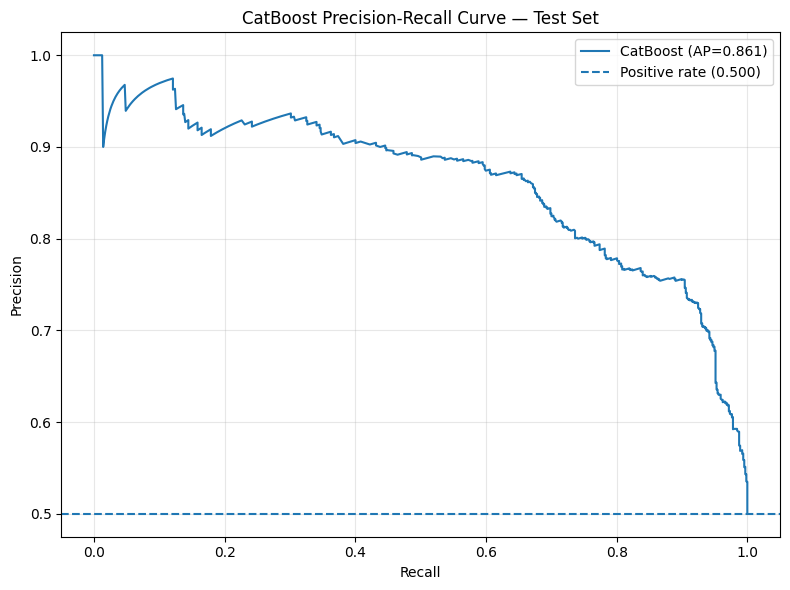

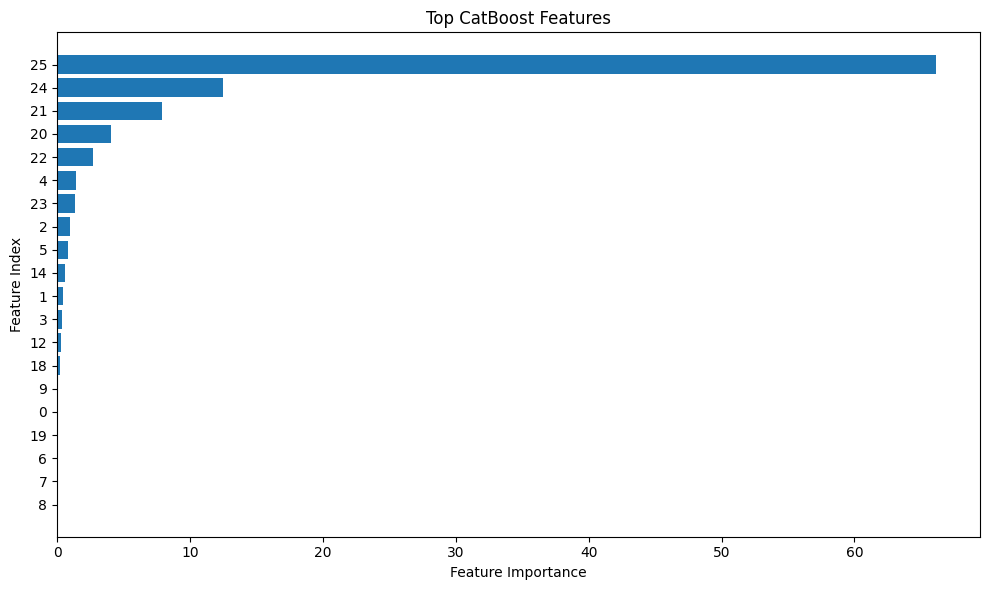


Saved model and results in: catboost_grid_results
Best model: catboost_grid_results\best_catboost.cbm
Grid results: catboost_grid_results\grid_search_results.csv


In [14]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_curve,
    confusion_matrix,
    roc_curve,
)

# ============================================================
# 1. CONFIGURATION
# ============================================================

RANDOM_SEED = 42
EARLY_STOPPING_ROUNDS = 100
OUTPUT_DIR = "catboost_grid_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Assumes these variables already exist:
# X_train, X_val, X_test, y_train, y_val, y_test
#
# No feature engineering or graph operations are performed here.

X_train = np.asarray(X_train, dtype=np.float32)
X_val = np.asarray(X_val, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

y_train = np.asarray(y_train).ravel().astype(int)
y_val = np.asarray(y_val).ravel().astype(int)
y_test = np.asarray(y_test).ravel().astype(int)

assert X_train.ndim == X_val.ndim == X_test.ndim == 2
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert set(np.unique(y_train)).issubset({0, 1})
assert set(np.unique(y_val)).issubset({0, 1})
assert set(np.unique(y_test)).issubset({0, 1})

print("Dataset shapes:")
print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)
print("Train positive rate:", y_train.mean())
print("Validation positive rate:", y_val.mean())
print("Test positive rate:", y_test.mean())


# ============================================================
# 2. HYPERPARAMETER GRID
# ============================================================
# 3 * 2 * 2 * 2 * 2 = 48 configurations.
# Early stopping limits unnecessary iterations.
#
# If runtime is too long, reduce the grid to 12-24 combinations.

PARAM_GRID = {
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.07],
    "l2_leaf_reg": [3, 7],
    "random_strength": [0.5, 1.0],
    "bagging_temperature": [0.0, 1.0],
}

ITERATION_OPTIONS = [500, 1000]


# ============================================================
# 3. THRESHOLD SELECTION
# ============================================================

def best_f1_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    if len(thresholds) == 0:
        return 0.5, 0.0

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_idx = int(np.argmax(f1_scores))
    return float(thresholds[best_idx]), float(f1_scores[best_idx])


# ============================================================
# 4. GRID SEARCH
# ============================================================

from itertools import product

grid_keys = list(PARAM_GRID.keys())
grid_values = [PARAM_GRID[k] for k in grid_keys]

all_combinations = list(product(*grid_values))
total_runs = len(all_combinations) * len(ITERATION_OPTIONS)

print(f"\nConfigurations to evaluate: {total_runs}")

search_results = []
best_ap = -np.inf
best_model = None
best_params = None
run_number = 0

for values in all_combinations:
    params = dict(zip(grid_keys, values))

    for iterations in ITERATION_OPTIONS:
        run_number += 1

        current_params = {
            **params,
            "iterations": iterations,
        }

        print(
            f"\n[{run_number}/{total_runs}] "
            f"Testing: {current_params}"
        )

        model = CatBoostClassifier(
            **current_params,
            loss_function="Logloss",
            eval_metric="PRAUC",
            random_seed=RANDOM_SEED,
            verbose=False,
            allow_writing_files=False,
            thread_count=-1,
        )

        model.fit(
            X_train,
            y_train,
            eval_set=(X_val, y_val),
            early_stopping_rounds=EARLY_STOPPING_ROUNDS,
            verbose=False,
        )

        val_probs = model.predict_proba(X_val)[:, 1]

        val_ap = average_precision_score(y_val, val_probs)
        val_auc = roc_auc_score(y_val, val_probs)

        # Store the actual best iteration when early stopping is used.
        best_iteration = model.get_best_iteration()
        if best_iteration is None or best_iteration < 0:
            best_iteration = iterations
        else:
            best_iteration += 1

        result = {
            **current_params,
            "best_iteration": best_iteration,
            "validation_AP": val_ap,
            "validation_ROC_AUC": val_auc,
        }
        search_results.append(result)

        print(
            f"Validation AP={val_ap:.5f} | "
            f"ROC-AUC={val_auc:.5f} | "
            f"Best iteration={best_iteration}"
        )

        if val_ap > best_ap:
            best_ap = val_ap
            best_params = {
                **params,
                "iterations": best_iteration,
            }
            best_model = model

            print("  --> New best model")


# ============================================================
# 5. SAVE GRID SEARCH RESULTS
# ============================================================

results_df = pd.DataFrame(search_results)
results_df = results_df.sort_values(
    "validation_AP", ascending=False
).reset_index(drop=True)

results_path = os.path.join(OUTPUT_DIR, "grid_search_results.csv")
results_df.to_csv(results_path, index=False)

print("\nTop 10 configurations:")
print(results_df.head(10).to_string(index=False))

print("\nBest hyperparameters:")
print(json.dumps(best_params, indent=2))
print(f"Best validation AP: {best_ap:.5f}")


# ============================================================
# 6. REFIT SELECTED CONFIGURATION ON TRAINING DATA
# ============================================================
# Keep validation data out of the fit here: it was used to choose
# hyperparameters and the threshold.
#
# We refit on X_train only, with the best iteration count.

best_model = CatBoostClassifier(
    **best_params,
    loss_function="Logloss",
    eval_metric="PRAUC",
    random_seed=RANDOM_SEED,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1,
)

best_model.fit(X_train, y_train, verbose=False)

model_path = os.path.join(OUTPUT_DIR, "best_catboost.cbm")
best_model.save_model(model_path)


# ============================================================
# 7. CHOOSE THRESHOLD ON VALIDATION DATA
# ============================================================

val_probs = best_model.predict_proba(X_val)[:, 1]

threshold, validation_f1 = best_f1_threshold(
    y_val, val_probs
)

print(f"\nValidation-selected F1 threshold: {threshold:.5f}")
print(f"Validation F1 at selected threshold: {validation_f1:.5f}")
print(
    "Validation AP:",
    f"{average_precision_score(y_val, val_probs):.5f}",
)
print(
    "Validation ROC-AUC:",
    f"{roc_auc_score(y_val, val_probs):.5f}",
)


# ============================================================
# 8. FINAL TEST EVALUATION
# ============================================================
# Test data is not used for tuning or threshold selection.

test_probs = best_model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_preds, labels=[0, 1]
).ravel()

test_metrics = {
    "threshold": threshold,
    "accuracy": accuracy_score(y_test, test_preds),
    "balanced_accuracy": balanced_accuracy_score(y_test, test_preds),
    "precision": precision_score(y_test, test_preds, zero_division=0),
    "recall": recall_score(y_test, test_preds, zero_division=0),
    "f1": f1_score(y_test, test_preds, zero_division=0),
    "specificity": tn / (tn + fp) if tn + fp else 0.0,
    "ROC_AUC": roc_auc_score(y_test, test_probs),
    "average_precision": average_precision_score(y_test, test_probs),
    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp),
}

print("\nFinal test metrics:")
print(pd.Series(test_metrics).to_string())

with open(
    os.path.join(OUTPUT_DIR, "test_metrics.json"),
    "w",
    encoding="utf-8",
) as f:
    json.dump(test_metrics, f, indent=2)


# ============================================================
# 9. PRECISION-RECALL CURVE
# ============================================================

precision, recall, _ = precision_recall_curve(y_test, test_probs)

plt.figure(figsize=(8, 6))
plt.plot(
    recall,
    precision,
    label=f"CatBoost (AP={test_metrics['average_precision']:.3f})",
)
plt.axhline(
    y=np.mean(y_test),
    linestyle="--",
    label=f"Positive rate ({np.mean(y_test):.3f})",
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("CatBoost Precision-Recall Curve — Test Set")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "precision_recall_curve.png"),
    dpi=150,
)
plt.show()


# ============================================================
# 10. FEATURE IMPORTANCE
# ============================================================

importances = best_model.get_feature_importance()

feature_importance_df = pd.DataFrame({
    "feature_index": np.arange(X_train.shape[1]),
    "importance": importances,
}).sort_values("importance", ascending=False)

feature_importance_df.to_csv(
    os.path.join(OUTPUT_DIR, "feature_importance.csv"),
    index=False,
)

plt.figure(figsize=(10, 6))
top_features = feature_importance_df.head(20).sort_values(
    "importance", ascending=True
)

plt.barh(
    top_features["feature_index"].astype(str),
    top_features["importance"],
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature Index")
plt.title("Top CatBoost Features")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "feature_importance.png"),
    dpi=150,
)
plt.show()

print(f"\nSaved model and results in: {OUTPUT_DIR}")
print("Best model:", model_path)
print("Grid results:", results_path)


# Eval

Device: cpu
Training examples: 1020
Validation examples: 1274
Test examples: 1274
Features per edge: 26

Training Random Forest...
RF validation F1=0.8076, threshold=0.43

Training Logistic Regression...
LR validation F1=0.7773, threshold=0.40

Training XGBoost...
XGBoost validation F1=0.8170, threshold=0.45

Training CatBoost...
0:	test: 0.8394136	best: 0.8394136 (0)	total: 146ms	remaining: 2m 25s
100:	test: 0.8772972	best: 0.8772972 (100)	total: 382ms	remaining: 3.4s
200:	test: 0.8776385	best: 0.8782029 (149)	total: 622ms	remaining: 2.47s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.8782028691
bestIteration = 149

Shrink model to first 150 iterations.
CatBoost validation F1=0.8211, threshold=0.40

Training GNN...
Epoch 001 | Loss 0.7181 | Val AP 0.7147
Epoch 010 | Loss 0.6211 | Val AP 0.7509
Epoch 020 | Loss 0.5757 | Val AP 0.8096
Epoch 030 | Loss 0.5006 | Val AP 0.8584
Epoch 040 | Loss 0.4576 | Val AP 0.8612
Epoch 050 | Loss 0.4488 | Val AP 0.8801
Epoch 060 |

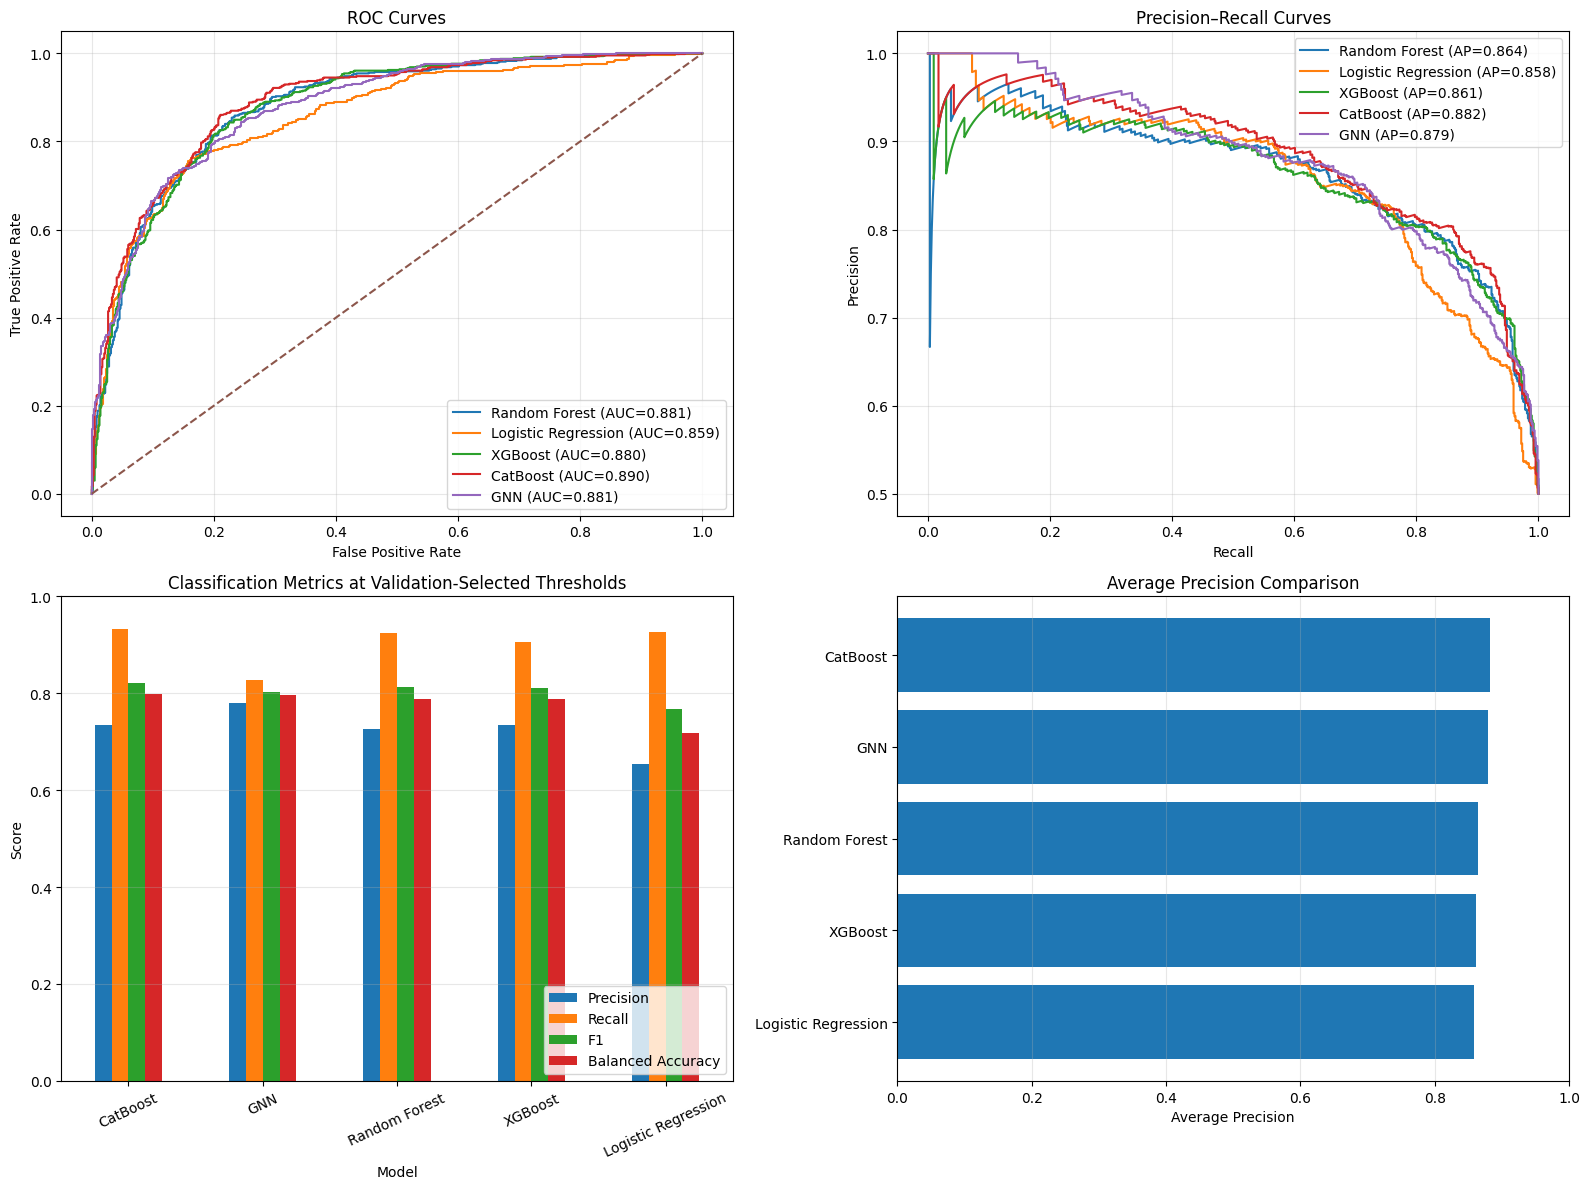

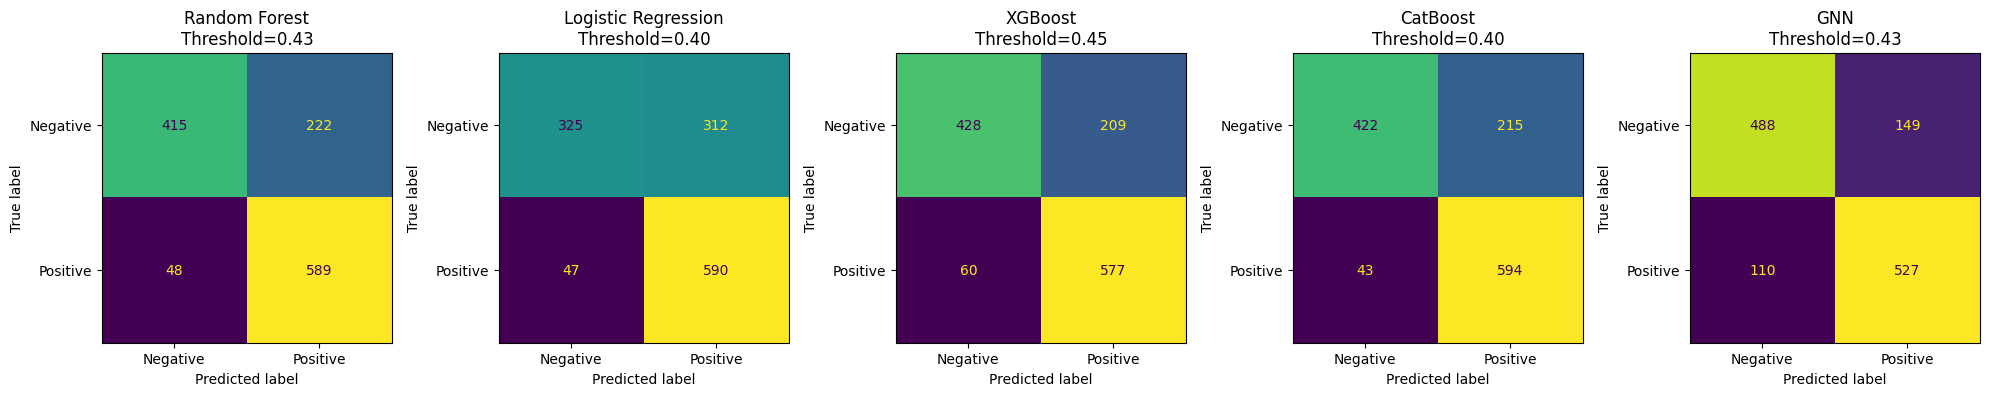

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)

print("\nTraining Random Forest...")
rf_model.fit(X_train, y_train)

rf_val_probs = rf_model.predict_proba(X_val)[:, 1]
rf_best_threshold, rf_val_f1 = find_best_f1_threshold(
    y_val, rf_val_probs
)

print(
    f"RF validation F1={rf_val_f1:.4f}, "
    f"threshold={rf_best_threshold:.2f}"
)


# ==========================================
# 4. LOGISTIC REGRESSION
# ==========================================

lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED,
    )),
])

print("\nTraining Logistic Regression...")
lr_model.fit(X_train, y_train)

lr_val_probs = lr_model.predict_proba(X_val)[:, 1]
lr_best_threshold, lr_val_f1 = find_best_f1_threshold(
    y_val, lr_val_probs
)

print(
    f"LR validation F1={lr_val_f1:.4f}, "
    f"threshold={lr_best_threshold:.2f}"
)


# ==========================================
# 5. XGBOOST
# ==========================================

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=SEED,
    n_jobs=-1,
)

print("\nTraining XGBoost...")
xgb_model.fit(X_train, y_train)

xgb_val_probs = xgb_model.predict_proba(X_val)[:, 1]
xgb_best_threshold, xgb_val_f1 = find_best_f1_threshold(
    y_val, xgb_val_probs
)

print(
    f"XGBoost validation F1={xgb_val_f1:.4f}, "
    f"threshold={xgb_best_threshold:.2f}"
)


# ==========================================
# 6. CATBOOST
# ==========================================

cat_model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.03,
    loss_function="Logloss",
    eval_metric="AUC",
    l2_leaf_reg=3.0,
    random_seed=SEED,
    verbose=100,
    allow_writing_files=False,
    thread_count=-1,
)

print("\nTraining CatBoost...")
cat_model.fit(
    X_train,
    y_train,
    eval_set=(X_val, y_val),
    early_stopping_rounds=100,
    verbose=100,
)

cat_val_probs = cat_model.predict_proba(X_val)[:, 1]
cat_best_threshold, cat_val_f1 = find_best_f1_threshold(
    y_val, cat_val_probs
)

print(
    f"CatBoost validation F1={cat_val_f1:.4f}, "
    f"threshold={cat_best_threshold:.2f}"
)


# ==========================================
# 7. GNN MODEL
# ==========================================


# Put split data and engineered features on the same device.
train_data = train_data.to(device)
val_data = val_data.to(device)
test_data = test_data.to(device)

train_edge_features = torch.as_tensor(
    X_train, dtype=torch.float32, device=device
)
val_edge_features = torch.as_tensor(
    X_val, dtype=torch.float32, device=device
)
test_edge_features = torch.as_tensor(
    X_test, dtype=torch.float32, device=device
)

model = Net(
    in_channels=train_data.x.size(1),
    hidden_channels=32,
    out_channels=16,
    edge_feature_channels=X_train.shape[1],
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.005,
    weight_decay=1e-4,
)

criterion = nn.BCEWithLogitsLoss()

train_labels = train_data.edge_label.float()
val_labels = val_data.edge_label.float()

# Early stopping monitors validation average precision.
# Test data is not used for model selection.
MAX_EPOCHS = 200
PATIENCE = 20

best_val_ap = -np.inf
best_epoch = 0
best_state = None
epochs_without_improvement = 0

print("\nTraining GNN...")

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    optimizer.zero_grad()

    z = model.encode(
        train_data.x,
        train_data.edge_index,
    )

    train_logits = model.decode(
        z,
        train_data.edge_label_index,
        train_edge_features,
    )

    loss = criterion(train_logits, train_labels)
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(), max_norm=2.0
    )

    optimizer.step()

    # Validate
    model.eval()

    with torch.no_grad():
        z_val = model.encode(
            val_data.x,
            val_data.edge_index,
        )

        val_logits = model.decode(
            z_val,
            val_data.edge_label_index,
            val_edge_features,
        )

        val_probs = torch.sigmoid(val_logits).cpu().numpy()

    val_ap = average_precision_score(y_val, val_probs)

    if val_ap > best_val_ap + 1e-5:
        best_val_ap = val_ap
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Loss {loss.item():.4f} | "
            f"Val AP {val_ap:.4f}"
        )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

if best_state is None:
    raise RuntimeError("GNN training did not produce a checkpoint.")

model.load_state_dict(best_state)
model.eval()

print(
    f"Best GNN epoch={best_epoch}, "
    f"validation AP={best_val_ap:.4f}"
)

# Final validation predictions for threshold selection.
with torch.no_grad():
    z_val = model.encode(
        val_data.x,
        val_data.edge_index,
    )

    gnn_val_probs = torch.sigmoid(
        model.decode(
            z_val,
            val_data.edge_label_index,
            val_edge_features,
        )
    ).cpu().numpy()

gnn_best_threshold, gnn_val_f1 = find_best_f1_threshold(
    y_val, gnn_val_probs
)

print(
    f"GNN validation F1={gnn_val_f1:.4f}, "
    f"threshold={gnn_best_threshold:.2f}"
)


# ==========================================
# 8. FINAL TEST PREDICTIONS
# ==========================================
# Evaluate the selected models on test data once.
# Do not use these results to tune the models.

models = {
    "Random Forest": rf_model,
    "Logistic Regression": lr_model,
    "XGBoost": xgb_model,
    "CatBoost": cat_model,
}

thresholds = {
    "Random Forest": rf_best_threshold,
    "Logistic Regression": lr_best_threshold,
    "XGBoost": xgb_best_threshold,
    "CatBoost": cat_best_threshold,
    "GNN": gnn_best_threshold,
}

predictions = {}

for name, fitted_model in models.items():
    probabilities = fitted_model.predict_proba(X_test)[:, 1]

    predictions[name] = {
        "y_true": y_test,
        "y_probs": probabilities,
        "y_pred": (
            probabilities >= thresholds[name]
        ).astype(int),
        "threshold": thresholds[name],
    }

# GNN test predictions use the best validation-selected checkpoint.
with torch.no_grad():
    z_test = model.encode(
        test_data.x,
        test_data.edge_index,
    )

    gnn_test_probs = torch.sigmoid(
        model.decode(
            z_test,
            test_data.edge_label_index,
            test_edge_features,
        )
    ).cpu().numpy()

predictions["GNN"] = {
    "y_true": y_test,
    "y_probs": gnn_test_probs,
    "y_pred": (
        gnn_test_probs >= gnn_best_threshold
    ).astype(int),
    "threshold": gnn_best_threshold,
}


# ==========================================
# 9. CALCULATE TEST METRICS
# ==========================================

rows = []

for name, result in predictions.items():
    yt = result["y_true"]
    yp = result["y_pred"]
    probs = result["y_probs"]

    tn, fp, fn, tp = confusion_matrix(
        yt, yp, labels=[0, 1]
    ).ravel()

    rows.append({
        "Model": name,
        "Threshold": result["threshold"],
        "Accuracy": accuracy_score(yt, yp),
        "Balanced Accuracy": balanced_accuracy_score(yt, yp),
        "Precision": precision_score(
            yt, yp, zero_division=0
        ),
        "Recall": recall_score(
            yt, yp, zero_division=0
        ),
        "Specificity": (
            tn / (tn + fp) if tn + fp else 0.0
        ),
        "F1": f1_score(yt, yp, zero_division=0),
        "ROC-AUC": roc_auc_score(yt, probs),
        "Average Precision": average_precision_score(yt, probs),
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
    })

results_df = (
    pd.DataFrame(rows)
    .sort_values("Average Precision", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 110)
print("FINAL TEST RESULTS — MODELS SELECTED USING VALIDATION")
print("=" * 110)

display_df = results_df.copy()

score_columns = [
    "Accuracy", "Balanced Accuracy", "Precision",
    "Recall", "Specificity", "F1", "ROC-AUC",
    "Average Precision",
]

display_df[score_columns] = display_df[score_columns].round(4)
display_df["Threshold"] = display_df["Threshold"].round(3)

print(display_df.to_string(index=False))


# ==========================================
# 10. PLOT COMPARISON DASHBOARD
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ROC curves
ax = axes[0, 0]

for name, result in predictions.items():
    fpr, tpr, _ = roc_curve(
        result["y_true"], result["y_probs"]
    )

    model_auc = roc_auc_score(
        result["y_true"], result["y_probs"]
    )

    ax.plot(fpr, tpr, label=f"{name} (AUC={model_auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--")
ax.set_title("ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(True, alpha=0.3)

# Precision-recall curves
ax = axes[0, 1]

for name, result in predictions.items():
    precision, recall, _ = precision_recall_curve(
        result["y_true"], result["y_probs"]
    )

    ap = average_precision_score(
        result["y_true"], result["y_probs"]
    )

    ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

ax.set_title("Precision–Recall Curves")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
ax.grid(True, alpha=0.3)

# Threshold-dependent metrics
ax = axes[1, 0]

results_df.set_index("Model")[
    ["Precision", "Recall", "F1", "Balanced Accuracy"]
].plot(kind="bar", ax=ax)

ax.set_title("Classification Metrics at Validation-Selected Thresholds")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=25)
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)

# Average precision comparison
ax = axes[1, 1]

ap_sorted = results_df.sort_values(
    "Average Precision", ascending=True
)

ax.barh(
    ap_sorted["Model"],
    ap_sorted["Average Precision"],
)

ax.set_title("Average Precision Comparison")
ax.set_xlabel("Average Precision")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


# ==========================================
# 11. CONFUSION MATRICES
# ==========================================

n_models = len(predictions)

fig, axes = plt.subplots(
    1, n_models,
    figsize=(4 * n_models, 4),
)

axes = np.atleast_1d(axes)

for ax, (name, result) in zip(axes, predictions.items()):
    cm = confusion_matrix(
        result["y_true"],
        result["y_pred"],
        labels=[0, 1],
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"],
    ).plot(
        ax=ax,
        values_format="d",
        colorbar=False,
    )

    ax.set_title(
        f"{name}\nThreshold={result['threshold']:.2f}"
    )

plt.tight_layout()
plt.show()

# Available outputs:
# results_df  -> test metrics for every model
# predictions -> test labels, probabilities, predictions, thresholds
# model       -> trained GNN
# rf_model, lr_model, xgb_model, cat_model -> trained classifiers
